# GTEx V11 brain-region prediction — Arai's final analysis
**BMEN 600 | Arai Jenkins | Group 23**

This notebook covers Arai's **preprocessing** and **model development/evaluation** sections. It retains the six pilot directions (three reciprocal pairs). This is a GTEx-only analysis of regional expression, with no Parkinson's or disease classification component.

**Run:** Runtime → Run all on a standard CPU runtime. The notebook downloads the team's existing public release, validates its SHA-256, and exports results. It never writes to GitHub.

**Prespecified design:** five repeated 80/20 donor holdouts; three-fold inner cross-validation; ridge penalties 1, 10, 100, 1000. Seed 42 is the reference result; four additional splits assess sensitivity. Outer splits are **repeated holdouts, not five-fold cross-validation**. A second analysis uses identical target-gene identities in reciprocal directions. All gene selection and fitted scaling occur inside the appropriate training partition. Existing pilot numbers are not reused as final results.


In [1]:
from pathlib import Path
import os, json, gzip, hashlib, zipfile, shutil, platform, time
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown

STARTED = time.time()
SEEDS = [42, 142, 242, 342, 442]
ALPHAS = [1.0, 10.0, 100.0, 1000.0]
TEST_FRACTION, INNER_FOLDS = 0.20, 3
N_SOURCE, N_TARGET, MIN_PAIRED = 500, 1000, 60
EXPRESSION_LOGCPM, MIN_EXPRESSION_FRACTION, MIN_TRAIN_VARIANCE = 1.0, 0.20, 1e-8
N_BOOTSTRAPS, SST_EPSILON = 1000, 1e-12
PAIRS = [
    ('caudate_basal_ganglia', 'putamen_basal_ganglia'),
    ('putamen_basal_ganglia', 'caudate_basal_ganglia'),
    ('cortex', 'frontal_cortex_ba9'), ('frontal_cortex_ba9', 'cortex'),
    ('cerebellum', 'cerebellar_hemisphere'), ('cerebellar_hemisphere', 'cerebellum'),
]
LABELS = {
    'amygdala':'Amygdala', 'anterior_cingulate_cortex_ba24':'Anterior cingulate cortex (BA24)',
    'caudate_basal_ganglia':'Caudate', 'putamen_basal_ganglia':'Putamen',
    'cortex':'Cortex', 'frontal_cortex_ba9':'Frontal cortex (BA9)',
    'cerebellum':'Cerebellum', 'cerebellar_hemisphere':'Cerebellar hemisphere',
    'hippocampus':'Hippocampus', 'hypothalamus':'Hypothalamus',
    'nucleus_accumbens_basal_ganglia':'Nucleus accumbens', 'substantia_nigra':'Substantia nigra',
    'spinal_cord_cervical_c-1':'Spinal cord (excluded)',
}
PREFIX = 'gene_reads_adult_gtex_v11_brain_'
DATA_URL = 'https://github.com/ellamichele/BMEN600Group23/releases/download/v1.0-data/gene_reads_GTEx.zip'
EXPECTED_SHA256 = 'b5e3418a3b880796845a6bd5f7fd01f4856dfc97655bfb4fea6502c8721533b4'
BASE = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = Path(os.environ.get('GTEX_OUTPUT_DIR', str(BASE/'gtex_arai_results')))
INPUT = Path(os.environ.get('GTEX_INPUT_DIR', str(BASE/'gtex_arai_input')))
OUT.mkdir(parents=True,exist_ok=True); INPUT.mkdir(parents=True,exist_ok=True)
for folder in ['tables','figures','audit','predictions','models','documents']:
    (OUT/folder).mkdir(exist_ok=True)
VERSIONS = {p:version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','requests','threadpoolctl','ipython']}
print('Python:',platform.python_version(),'Packages:',VERSIONS)
plt.rcParams.update({'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})


Python: 3.13.18 Packages: {'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'requests': '2.32.4', 'threadpoolctl': '3.7.0', 'ipython': '7.34.0'}


## 1. Verify the exact dataset
The archive includes cervical spinal cord, which is excluded from all brain-region figures and models. A changed archive hash stops the analysis. If the release is unavailable, upload the existing `gene_reads_GTEx.zip` through Colab's Files panel, then rerun this cell. The default path is `/content/gene_reads_GTEx.zip`.


In [2]:
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

ZIP_PATH=Path(os.environ.get('GTEX_INPUT_ZIP',str(BASE/'gene_reads_GTEx.zip')))
if not ZIP_PATH.exists():
    partial=ZIP_PATH.with_suffix('.zip.partial')
    print('Downloading existing public team release ...',flush=True)
    with requests.get(DATA_URL,stream=True,timeout=(30,180)) as response:
        response.raise_for_status()
        with partial.open('wb') as stream:
            for chunk in response.iter_content(1024*1024):
                if chunk: stream.write(chunk)
    if sha256_file(partial)!=EXPECTED_SHA256: raise ValueError('Downloaded data hash mismatch.')
    partial.replace(ZIP_PATH)
archive_hash=sha256_file(ZIP_PATH)
if archive_hash!=EXPECTED_SHA256: raise ValueError('Input archive SHA-256 mismatch. Stop and investigate.')
with zipfile.ZipFile(ZIP_PATH) as archive:
    members=[m for m in archive.infolist() if not m.is_dir() and m.filename.endswith('.gct.gz')]
    names=[Path(m.filename).name for m in members]
    if len(names)!=13 or set(names)!={PREFIX+r+'.gct.gz' for r in LABELS}:
        raise ValueError('Expected exactly the 13 original named region files, without duplicates.')
    for member in members:
        # Known basenames only: no archive path can escape INPUT.
        with archive.open(member) as source, (INPUT/Path(member.filename).name).open('wb') as target:
            shutil.copyfileobj(source,target)
print('Verified input SHA-256:',archive_hash)


Verified input SHA-256: b5e3418a3b880796845a6bd5f7fd01f4856dfc97655bfb4fea6502c8721533b4


## 2. Audit and normalize read counts
Use complete versioned Ensembl IDs in `Name`, not gene symbols. Duplicate symbols are permitted; duplicate gene IDs, sample IDs or donor-region observations cause an error. Missing/negative/nonfinite counts and zero libraries also stop the notebook. There is no imputation or silent averaging of donor samples.

Library size is the sum of **all gene rows in the original tissue file, before gene filtering**. Each sample is transformed separately to log2(1 + 10^6 × count/library size). This sample-local calculation does not estimate a parameter across donors. Store normalized matrices as float32 after float64 normalization. Extract donor IDs from the first two hyphen-separated sample-ID fields. Align genes by full identifiers, not by row position.


In [3]:
def load_region(path):
    with gzip.open(path,'rt',encoding='utf-8') as stream:
        gct=stream.readline().strip(); shape=stream.readline().split()
        header=stream.readline().rstrip('\r\n').split('\t')
    if gct!='#1.2' or len(shape)!=2: raise ValueError(f'Unsupported GCT: {path.name}')
    ng,ns=map(int,shape)
    if len(header)!=ns+2 or header[:2]!=['Name','Description']: raise ValueError('GCT columns mismatch')
    if len(set(header[2:]))!=ns: raise ValueError('Duplicate sample IDs')
    table=pd.read_csv(path,sep='\t',skiprows=2)
    if table.shape!=(ng,ns+2): raise ValueError('GCT dimension mismatch')
    genes=table['Name'].astype('string')
    if genes.isna().any() or genes.duplicated().any(): raise ValueError('Missing/duplicate full gene IDs')
    counts=table.iloc[:,2:].to_numpy(dtype=np.float64)
    if not np.isfinite(counts).all() or (counts<0).any(): raise ValueError('Invalid counts')
    libraries=counts.sum(axis=0,dtype=np.float64)
    if (libraries<=0).any(): raise ValueError('Zero read library')
    donors=[]
    for sample in header[2:]:
        bits=sample.split('-')
        if len(bits)<3 or bits[0]!='GTEX' or not bits[1]: raise ValueError('Unexpected sample ID')
        donors.append('-'.join(bits[:2]))
    if len(set(donors))!=ns: raise ValueError('Multiple donor-region samples require a documented resolution.')
    region=path.name[len(PREFIX):-len('.gct.gz')]
    frame=pd.DataFrame(np.log2(1+counts/libraries*1e6).T.astype(np.float32),index=donors,columns=genes)
    frame=frame.sort_index().sort_index(axis=1)
    rec=dict(region=region,included=not region.startswith('spinal_cord'),n_genes=ng,n_samples=ns,
             n_donors=len(frame),duplicate_donor_samples=ns-len(set(donors)),
             min_library_reads=float(libraries.min()),median_library_reads=float(np.median(libraries)),
             max_library_reads=float(libraries.max()),file=path.name,sha256=sha256_file(path))
    samples=pd.DataFrame({'region':region,'sample_id':header[2:],'donor_id':donors,'library_reads':libraries})
    symbols=pd.Series(table['Description'].fillna('').astype(str).values,index=genes)
    return frame,rec,samples,symbols

regions,records,sample_rows,symbols={ },[],[],{}
for region in sorted(LABELS):
    frame,rec,samples,sym=load_region(INPUT/(PREFIX+region+'.gct.gz'))
    records.append(rec); sample_rows.append(samples)
    if rec['included']: regions[region]=frame; symbols[region]=sym
    print(region,rec['n_donors'],'donors',flush=True)
inventory=pd.DataFrame(records)
active_inventory=inventory.loc[inventory.included].copy()
all_donors=sorted(set().union(*(set(x.index) for x in regions.values())))
for a,b in PAIRS:
    if set(regions[a].columns)!=set(regions[b].columns): raise ValueError('Gene ID sets differ; review alignment.')
inventory.to_csv(OUT/'audit/input_inventory.csv',index=False)
active_inventory.to_csv(OUT/'tables/table_1_dataset.csv',index=False)
pd.concat(sample_rows).to_csv(OUT/'audit/sample_inventory.csv',index=False)
dataset_summary={'included_regions':len(regions),'unique_donors':len(all_donors),
                 'tissue_records':int(active_inventory.n_samples.sum()),
                 'excluded_region':'spinal_cord_cervical_c-1',
                 'duplicate_donor_region_records':int(active_inventory.duplicate_donor_samples.sum())}
(OUT/'audit/dataset_summary.json').write_text(json.dumps(dataset_summary,indent=2),encoding='utf-8')
print('Verified dataset summary:',dataset_summary)
display(active_inventory[['region','n_genes','n_samples','n_donors','duplicate_donor_samples']])


amygdala 181 donors
anterior_cingulate_cortex_ba24 233 donors
caudate_basal_ganglia 300 donors
cerebellar_hemisphere 277 donors
cerebellum 266 donors
cortex 270 donors
frontal_cortex_ba9 269 donors
hippocampus 255 donors
hypothalamus 257 donors
nucleus_accumbens_basal_ganglia 285 donors
putamen_basal_ganglia 254 donors
spinal_cord_cervical_c-1 204 donors
substantia_nigra 183 donors
Verified dataset summary: {'included_regions': 12, 'unique_donors': 385, 'tissue_records': 3030, 'excluded_region': 'spinal_cord_cervical_c-1', 'duplicate_donor_region_records': 0}


,region,n_genes,n_samples,n_donors,duplicate_donor_samples
0,amygdala,74628,181,181,0
1,anterior_cingulate_cortex_ba24,74628,233,233,0
2,caudate_basal_ganglia,74628,300,300,0
3,cerebellar_hemisphere,74628,277,277,0
4,cerebellum,74628,266,266,0
5,cortex,74628,270,270,0
6,frontal_cortex_ba9,74628,269,269,0
7,hippocampus,74628,255,255,0
8,hypothalamus,74628,257,257,0
9,nucleus_accumbens_basal_ganglia,74628,285,285,0


## 3. Training-only selection and nested development
Keep genes with log2(CPM+1) > 1 (CPM > 1) in at least 20% of **training donors**, and training sample variance > 10^-8. Rank eligible genes by descending variance, resolving ties by full ID; retain up to 500 source and 1,000 target genes. Standardize predictors with training means and population standard deviations. Outcomes are not standardized. Ridge fits an intercept.

Inner three-fold cross-validation chooses alpha by pooled validation MSE across donors and selected target genes. Gene selection and scaling are repeated inside every inner training fold. Refit selection, scaling and the chosen model on all development donors, then evaluate the untouched outer test donors.

**Common-target sensitivity:** require eligibility in both regions on the same training donors, rank by the mean of their two regional variances, and choose up to 1,000 target genes. Reciprocal directions then predict identical gene IDs. Source predictors remain separately selected. This controls gene identity, not tissue-specific outcome variance or confounding.


In [4]:
def eligible_variance(train):
    var=train.var(axis=0,ddof=1)
    expressed=(train>EXPRESSION_LOGCPM).mean(axis=0)>=MIN_EXPRESSION_FRACTION
    return var.loc[expressed & (var>MIN_TRAIN_VARIANCE)]
def rank_genes(values,count):
    ranked=values.sort_index().sort_values(ascending=False,kind='stable')
    if len(ranked)<10: raise ValueError('Fewer than 10 eligible genes')
    return ranked.index[:count].tolist()
def select_genes(xt,yt,mode):
    xv,yv=eligible_variance(xt),eligible_variance(yt)
    xg=rank_genes(xv,N_SOURCE)
    if mode=='primary': yg=rank_genes(yv,N_TARGET)
    elif mode=='common_targets':
        common=xv.index.intersection(yv.index).sort_values()
        yg=rank_genes((xv.loc[common]+yv.loc[common])/2,N_TARGET)
    else: raise ValueError(mode)
    return xg,yg
def fit_scaled_ridge(x,y,alpha):
    scaler=StandardScaler()
    z=scaler.fit_transform(np.asarray(x,dtype=np.float64))
    model=Ridge(alpha=float(alpha),fit_intercept=True,solver='cholesky').fit(z,np.asarray(y,dtype=np.float64))
    return scaler,model
def develop_model(xdev,ydev,seed,mode):
    if not xdev.index.equals(ydev.index): raise ValueError('Unmatched development donors')
    rows,splits,selections=[],[],[]
    cv=KFold(n_splits=INNER_FOLDS,shuffle=True,random_state=seed+1000)
    for fold,(it,iv) in enumerate(cv.split(xdev),1):
        xt,yt=xdev.iloc[it],ydev.iloc[it]
        xg,yg=select_genes(xt,yt,mode)
        assert set(xt.index).isdisjoint(xdev.iloc[iv].index)
        splits.append({'inner_fold':fold,'train_donors':xt.index.tolist(),'validation_donors':xdev.iloc[iv].index.tolist()})
        selections.append({'stage':f'inner_{fold}','source_genes':xg,'target_genes':yg})
        scaler=StandardScaler().fit(xt[xg].to_numpy(dtype=np.float64))
        Xtr=scaler.transform(xt[xg].to_numpy(dtype=np.float64))
        Xv=scaler.transform(xdev.iloc[iv][xg].to_numpy(dtype=np.float64))
        Ytr=yt[yg].to_numpy(dtype=np.float64); Yv=ydev.iloc[iv][yg].to_numpy(dtype=np.float64)
        for alpha in ALPHAS:
            model=Ridge(alpha=alpha,fit_intercept=True,solver='cholesky').fit(Xtr,Ytr)
            error=Yv-model.predict(Xv)
            rows.append({'inner_fold':fold,'alpha':alpha,'sse':float(np.sum(error**2)),
                         'n_values':int(error.size),'n_train':len(it),'n_validation':len(iv),
                         'n_source_genes':len(xg),'n_target_genes':len(yg)})
    losses=pd.DataFrame(rows).groupby('alpha',sort=True)[['sse','n_values']].sum()
    losses['mse']=losses.sse/losses.n_values
    alpha=float(losses.mse.idxmin())  # smaller alpha breaks an exact tie
    xg,yg=select_genes(xdev,ydev,mode)
    scaler,model=fit_scaled_ridge(xdev[xg],ydev[yg],alpha)
    selections.append({'stage':'development_refit','source_genes':xg,'target_genes':yg})
    return dict(scaler=scaler,model=model,xgenes=xg,ygenes=yg,alpha=alpha,
                inner_mse=float(losses.loc[alpha,'mse']),tuning=rows,inner_splits=splits,selections=selections,
                baseline=ydev[yg].to_numpy(dtype=np.float64).mean(axis=0))


## 4. Metrics and uncertainty
Compute R² separately for each selected target gene across held-out donors, then take the median. Retain negative values. Genes with test-set sum of squares ≤ 10^-12 have undefined R² and are excluded from its median; their count is reported. They remain in pooled error metrics.

The baseline predicts each target gene's **development-set mean**. Pooled squared-error skill = 1 − SSE_model / SSE_baseline over test donor–gene entries. This differs from ordinary R², whose denominator uses the test-set mean. MAE and RMSE use log2(CPM+1) units.

For seed 42, 1,000 bootstrap resamples draw whole test donors jointly across genes, predictions and baseline. Percentile 95% intervals are conditional on the fixed fitted model and split. Split-to-split spread is reported separately and is not a confidence interval. Overlapping repeated splits are not independent studies.


In [5]:
def gene_r2(y,p):
    sse=np.sum((y-p)**2,axis=0); sst=np.sum((y-y.mean(axis=0))**2,axis=0)
    return 1-np.divide(sse,sst,out=np.full(sse.shape,np.nan),where=sst>SST_EPSILON)
def metrics(y,p,b):
    r2=gene_r2(y,p); br2=gene_r2(y,b)
    mse=np.mean((y-p)**2); bmse=np.mean((y-b)**2)
    return dict(median_gene_r2=float(np.nanmedian(r2)),baseline_median_gene_r2=float(np.nanmedian(br2)),
                skill=float(1-mse/bmse) if bmse>SST_EPSILON else np.nan,
                model_mae=float(np.mean(np.abs(y-p))),model_rmse=float(np.sqrt(mse)),
                baseline_mae=float(np.mean(np.abs(y-b))),baseline_rmse=float(np.sqrt(bmse)),
                n_valid_r2_genes=int(np.isfinite(r2).sum()),n_undefined_r2_genes=int((~np.isfinite(r2)).sum()))
def donor_bootstrap(y,p,b,seed):
    rng=np.random.default_rng(seed); rows=[]
    for _ in range(N_BOOTSTRAPS):
        ix=rng.integers(0,len(y),len(y)); yt,pt,bt=y[ix],p[ix],b[ix]
        gr=gene_r2(yt,pt); bmse=np.mean((yt-bt)**2)
        rows.append((float(np.nanmedian(gr)) if np.isfinite(gr).any() else np.nan,
                     float(1-np.mean((yt-pt)**2)/bmse) if bmse>SST_EPSILON else np.nan))
    samples=np.asarray(rows); bounds=np.nanquantile(samples,[.025,.975],axis=0)
    return dict(r2_ci_low=float(bounds[0,0]),r2_ci_high=float(bounds[1,0]),
                skill_ci_low=float(bounds[0,1]),skill_ci_high=float(bounds[1,1]),
                bootstrap_valid_r2=int(np.isfinite(samples[:,0]).sum())),samples

# Synthetic data are only integrity checks, never empirical results.
y=np.array([[1.,3.,7.],[2.,5.,7.],[4.,9.,7.]])
assert np.allclose(gene_r2(y,y)[:2],1) and np.isnan(gene_r2(y,y)[2])
b=np.broadcast_to(np.array([2.,5.,7.]),y.shape)
assert metrics(y,b,b)['skill']==0
rng=np.random.default_rng(123); x=rng.normal(size=(18,25)); yy=rng.normal(size=(18,4))
sc,mo=fit_scaled_ridge(x,yy,10.); z=sc.transform(x)
dual=z@z.T@np.linalg.solve(z@z.T+10*np.eye(len(z)),yy-yy.mean(axis=0))+yy.mean(axis=0)
np.testing.assert_allclose(mo.predict(z),dual,rtol=1e-9,atol=1e-9)
f1=pd.DataFrame(rng.uniform(1.1,5,(25,30)),columns=[f'g{i:02}' for i in range(30)])
f2=pd.DataFrame(rng.uniform(1.1,5,(25,30)),columns=f1.columns)
assert select_genes(f1,f2,'common_targets')[1]==select_genes(f2,f1,'common_targets')[1]
print('Integrity checks passed: R2, undefined targets, baseline skill, ridge solution, common-target symmetry.')


Integrity checks passed: R2, undefined targets, baseline skill, ridge solution, common-target symmetry.


## 5. Fit all six directions on five donor splits
Reciprocal directions and sensitivity analyses share exact donor partitions and inner folds within each anatomical pair. Different anatomical pairs have different donor coverage. Do not interpret pair rankings as controlled comparisons of intrinsic biology.
The code checkpoints each completed aggregate evaluation and exports model arrays, gene IDs, tuning losses and test predictions. A rerun recomputes the analysis; it does not reuse old models.


In [6]:
rows,tuning_rows,split_records,selection_records,gene_rows=[],[],[],[],[]
with threadpool_limits(limits=2):
    for mode in ['primary','common_targets']:
        for pair_index,(source,target) in enumerate(PAIRS):
            ids=regions[source].index.intersection(regions[target].index).sort_values()
            if len(ids)<MIN_PAIRED: raise ValueError(f'Too few paired donors: {source}, {target}')
            xf,yf=regions[source].loc[ids],regions[target].loc[ids]
            for seed in SEEDS:
                di,ti=train_test_split(np.arange(len(ids)),test_size=TEST_FRACTION,random_state=seed)
                dev,test=ids[di],ids[ti]
                assert set(dev).isdisjoint(test) and len(dev)+len(test)==len(ids)
                fit=develop_model(xf.loc[dev],yf.loc[dev],seed,mode)
                xg,yg=fit['xgenes'],fit['ygenes']
                truth=yf.loc[test,yg].to_numpy(dtype=np.float64)
                pred=fit['model'].predict(fit['scaler'].transform(xf.loc[test,xg].to_numpy(dtype=np.float64)))
                baseline=np.broadcast_to(fit['baseline'],truth.shape).copy()
                tag=f'{mode}__{source}__to__{target}__seed{seed}'
                meta=dict(analysis=mode,source=source,target=target,seed=seed)
                row=dict(**meta,n_paired=len(ids),n_development=len(dev),n_test=len(test),
                         n_source_genes=len(xg),n_target_genes=len(yg),alpha=fit['alpha'],inner_mse=fit['inner_mse'],
                         **metrics(truth,pred,baseline))
                if seed==42:
                    ci,boot=donor_bootstrap(truth,pred,baseline,10000+pair_index)
                    row.update(ci); row['bootstrap_seed']=10000+pair_index
                    np.savez_compressed(OUT/'predictions'/f'{tag}_bootstrap.npz',samples=boot)
                np.savez_compressed(OUT/'predictions'/f'{tag}.npz',truth=truth,prediction=pred,baseline=baseline,
                                    test_donors=np.asarray(test,dtype=str),target_genes=np.asarray(yg,dtype=str))
                model,scaler=fit['model'],fit['scaler']
                np.savez_compressed(OUT/'models'/f'{tag}.npz',coef=model.coef_,intercept=model.intercept_,
                                    source_mean=scaler.mean_,source_scale=scaler.scale_,alpha=fit['alpha'],
                                    source_genes=np.asarray(xg,dtype=str),target_genes=np.asarray(yg,dtype=str))
                for inner in fit['inner_splits']:
                    assert set(inner['train_donors']).isdisjoint(test)
                    assert set(inner['validation_donors']).isdisjoint(test)
                tuning_rows.extend([{**meta,**r} for r in fit['tuning']])
                split_records.append({**meta,'development_donors':dev.tolist(),'test_donors':test.tolist(),
                                      'inner_seed':seed+1000,'inner_folds':fit['inner_splits']})
                selection_records.append({**meta,'selections':fit['selections']})
                gene_rows.append(pd.DataFrame({**meta,'gene_id':yg,'gene_symbol':symbols[target].loc[yg].values,
                    'r2':gene_r2(truth,pred),'baseline_r2':gene_r2(truth,baseline),
                    'mae':np.mean(np.abs(truth-pred),axis=0),'rmse':np.sqrt(np.mean((truth-pred)**2,axis=0))}))
                rows.append(row)
                pd.DataFrame(rows).to_csv(OUT/'tables/all_split_metrics.csv',index=False)
                print(f'{mode}: {source} -> {target}; seed={seed}; R2={row["median_gene_r2"]:.3f}; skill={row["skill"]:.3f}',flush=True)
results=pd.DataFrame(rows)
assert len(results)==60
pd.DataFrame(tuning_rows).to_csv(OUT/'audit/inner_cv_losses.csv',index=False)
(OUT/'audit/donor_splits.json').write_text(json.dumps(split_records,indent=2),encoding='utf-8')
(OUT/'audit/selected_genes.json').write_text(json.dumps(selection_records,indent=2),encoding='utf-8')
pd.concat(gene_rows,ignore_index=True).to_csv(OUT/'tables/per_gene_metrics.csv',index=False)
primary=results.query('analysis == "primary" and seed == 42').copy()
primary.to_csv(OUT/'tables/table_2_primary_reference.csv',index=False)
spread=results.groupby(['analysis','source','target'],sort=False).agg(
    n_splits=('seed','size'),median_r2=('median_gene_r2','median'),mean_r2=('median_gene_r2','mean'),
    sd_r2=('median_gene_r2','std'),min_r2=('median_gene_r2','min'),max_r2=('median_gene_r2','max'),
    median_skill=('skill','median'),min_skill=('skill','min'),max_skill=('skill','max')).reset_index()
spread.to_csv(OUT/'tables/table_3_split_sensitivity.csv',index=False)
common=results.query('analysis == "common_targets" and seed == 42').copy()
common.to_csv(OUT/'tables/table_4_common_target_reference.csv',index=False)
for seed in SEEDS:
    for a,b in PAIRS[::2]:
        matches=[s for s in selection_records if s['analysis']=='common_targets' and s['seed']==seed and (s['source'],s['target']) in [(a,b),(b,a)]]
        assert matches[0]['selections'][-1]['target_genes']==matches[1]['selections'][-1]['target_genes']
        ss=[s for s in split_records if s['analysis']=='primary' and s['seed']==seed and (s['source'],s['target']) in [(a,b),(b,a)]]
        assert ss[0]['test_donors']==ss[1]['test_donors']
print('All 60 evaluations complete; donor separation and reciprocal matching verified.')
display(primary.round(4)); display(spread.round(4))


primary: caudate_basal_ganglia -> putamen_basal_ganglia; seed=42; R2=0.514; skill=0.506
primary: caudate_basal_ganglia -> putamen_basal_ganglia; seed=142; R2=0.475; skill=0.469
primary: caudate_basal_ganglia -> putamen_basal_ganglia; seed=242; R2=0.526; skill=0.505
primary: caudate_basal_ganglia -> putamen_basal_ganglia; seed=342; R2=0.457; skill=0.470
primary: caudate_basal_ganglia -> putamen_basal_ganglia; seed=442; R2=0.693; skill=0.675
primary: putamen_basal_ganglia -> caudate_basal_ganglia; seed=42; R2=0.391; skill=0.350
primary: putamen_basal_ganglia -> caudate_basal_ganglia; seed=142; R2=0.535; skill=0.414
primary: putamen_basal_ganglia -> caudate_basal_ganglia; seed=242; R2=0.443; skill=0.354
primary: putamen_basal_ganglia -> caudate_basal_ganglia; seed=342; R2=0.388; skill=0.358
primary: putamen_basal_ganglia -> caudate_basal_ganglia; seed=442; R2=0.631; skill=0.532
primary: cortex -> frontal_cortex_ba9; seed=42; R2=0.516; skill=0.480
primary: cortex -> frontal_cortex_ba9; see

,analysis,source,target,seed,n_paired,n_development,n_test,n_source_genes,n_target_genes,alpha,...,baseline_mae,baseline_rmse,n_valid_r2_genes,n_undefined_r2_genes,r2_ci_low,r2_ci_high,skill_ci_low,skill_ci_high,bootstrap_valid_r2,bootstrap_seed
0,primary,caudate_basal_ganglia,putamen_basal_ganglia,42,233,186,47,500,1000,1000.0,...,1.0294,1.2771,1000,0,0.2872,0.6750,0.3310,0.6458,1000.0,10000.0
5,primary,putamen_basal_ganglia,caudate_basal_ganglia,42,233,186,47,500,1000,1000.0,...,0.9366,1.1954,1000,0,0.1321,0.5980,0.2031,0.4931,1000.0,10001.0
10,primary,cortex,frontal_cortex_ba9,42,194,155,39,500,1000,1000.0,...,0.8454,1.1115,1000,0,0.2675,0.6406,0.3338,0.6073,1000.0,10002.0
15,primary,frontal_cortex_ba9,cortex,42,194,155,39,500,1000,1000.0,...,0.7325,0.9626,1000,0,0.1260,0.4077,0.2882,0.4579,1000.0,10003.0
20,primary,cerebellum,cerebellar_hemisphere,42,222,177,45,500,1000,1000.0,...,0.6824,0.9152,1000,0,0.1873,0.3231,0.3225,0.4266,1000.0,10004.0
25,primary,cerebellar_hemisphere,cerebellum,42,222,177,45,500,1000,100.0,...,0.6663,0.8975,1000,0,0.0907,0.3518,0.2627,0.4106,1000.0,10005.0


,analysis,source,target,n_splits,median_r2,mean_r2,sd_r2,min_r2,max_r2,median_skill,min_skill,max_skill
0,primary,caudate_basal_ganglia,putamen_basal_ganglia,5,0.5144,0.5331,0.0937,0.4570,0.6930,0.5046,0.4687,0.6745
1,primary,putamen_basal_ganglia,caudate_basal_ganglia,5,0.4428,0.4774,0.1043,0.3877,0.6309,0.3582,0.3496,0.5322
2,primary,cortex,frontal_cortex_ba9,5,0.4009,0.4107,0.0904,0.3056,0.5158,0.4570,0.3653,0.4796
3,primary,frontal_cortex_ba9,cortex,5,0.3256,0.3231,0.0175,0.2954,0.3415,0.3547,0.3444,0.3778
4,primary,cerebellum,cerebellar_hemisphere,5,0.2866,0.2792,0.0176,0.2516,0.2957,0.3744,0.3593,0.4174
5,primary,cerebellar_hemisphere,cerebellum,5,0.3031,0.3019,0.0286,0.2697,0.3431,0.3821,0.3398,0.4369
6,common_targets,caudate_basal_ganglia,putamen_basal_ganglia,5,0.5098,0.5288,0.0899,0.4612,0.6834,0.4988,0.4638,0.6679
7,common_targets,putamen_basal_ganglia,caudate_basal_ganglia,5,0.4427,0.5006,0.1166,0.4042,0.6810,0.4232,0.4090,0.6083
8,common_targets,cortex,frontal_cortex_ba9,5,0.3804,0.3885,0.0866,0.2830,0.4835,0.4462,0.3452,0.4642
9,common_targets,frontal_cortex_ba9,cortex,5,0.3998,0.3909,0.0375,0.3377,0.4383,0.3782,0.3602,0.4117


## 6. Figures for the final paper
Figure 1 includes only the 12 retained brain regions. Figure 2 contrasts ridge and the development-mean baseline, with conditional donor-bootstrap intervals for seed 42. Figure 3 shows all five split results and the common-target analysis; the dots are not independent studies.


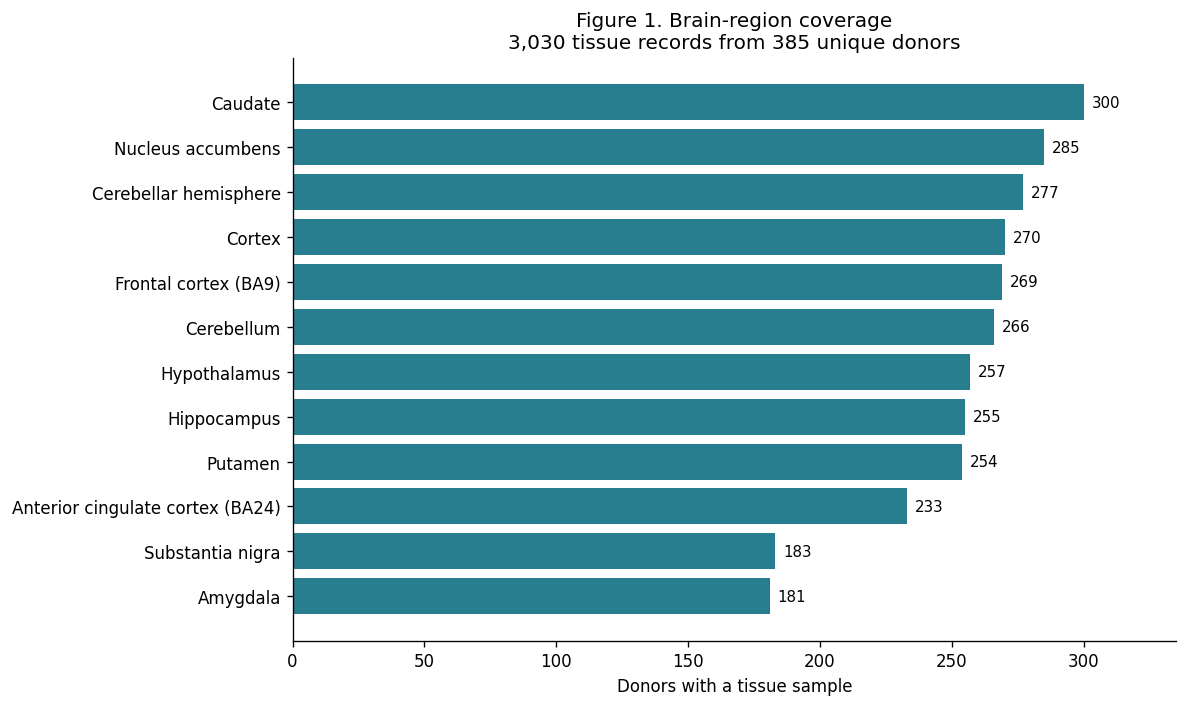

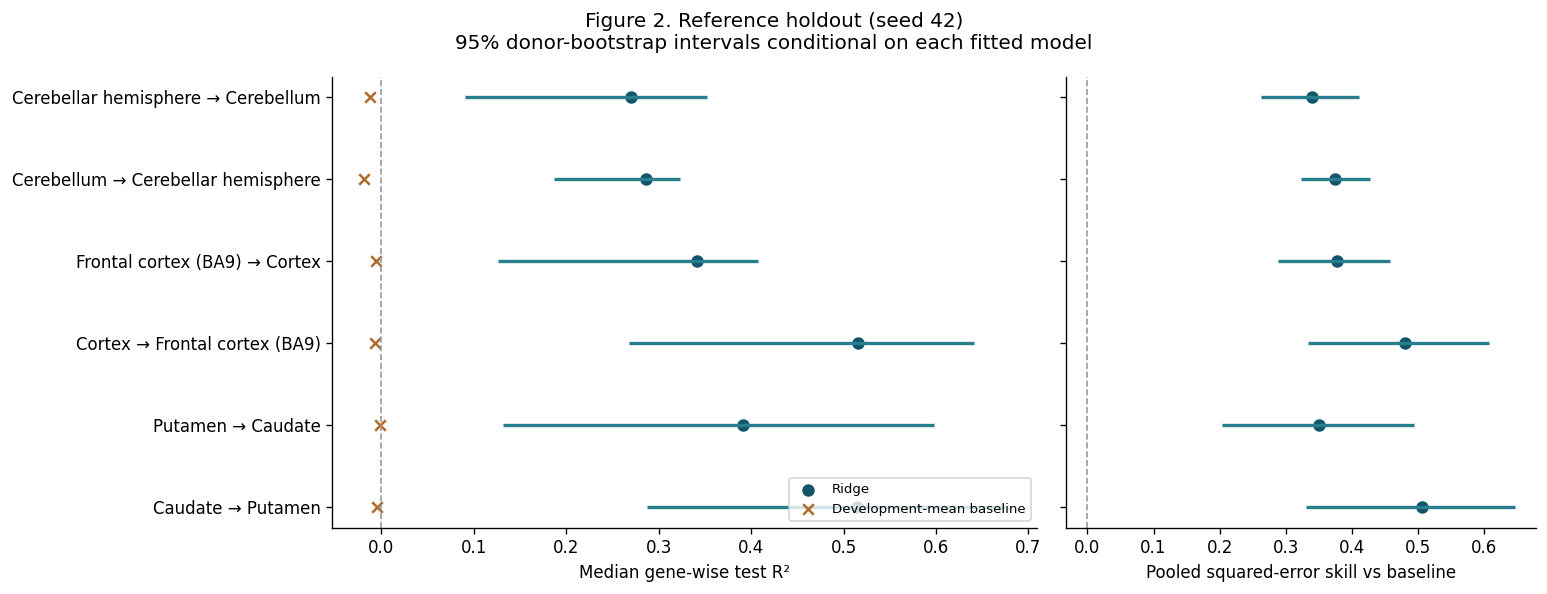

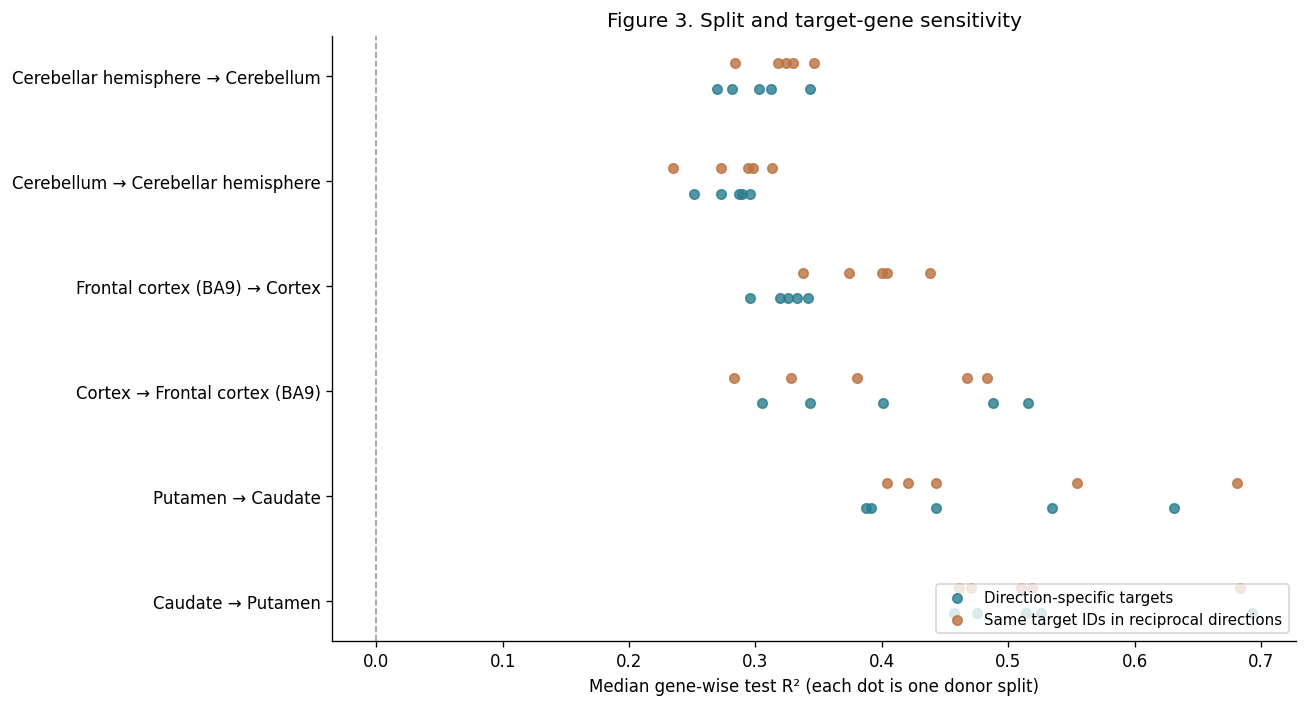

In [7]:
def label(r): return LABELS.get(r,r.replace('_',' '))
def direction(a,b): return label(a)+' → '+label(b)
def save_figure(fig,name):
    fig.savefig(OUT/'figures'/f'{name}.png',dpi=220,bbox_inches='tight')
    fig.savefig(OUT/'figures'/f'{name}.svg',bbox_inches='tight')
    plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(10,6)); s=active_inventory.sort_values('n_donors')
ax.barh([label(r) for r in s.region],s.n_donors,color='#287d8e')
for i,n in enumerate(s.n_donors): ax.text(n+3,i,str(n),va='center',fontsize=9)
ax.set(xlabel='Donors with a tissue sample',xlim=(0,int(s.n_donors.max())+35),
       title=f'Figure 1. Brain-region coverage\n{dataset_summary["tissue_records"]:,} tissue records from {len(all_donors)} unique donors')
fig.tight_layout(); save_figure(fig,'figure_1_dataset')
r=primary.copy().reset_index(drop=True); yy=np.arange(len(r))
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True,gridspec_kw={'width_ratios':[1.5,1]})
axes[0].hlines(yy,r.r2_ci_low,r.r2_ci_high,color='#287d8e',lw=2)
axes[0].scatter(r.median_gene_r2,yy,color='#125669',s=42,label='Ridge')
axes[0].scatter(r.baseline_median_gene_r2,yy,marker='x',color='#b06a2e',s=40,label='Development-mean baseline')
axes[0].set_yticks(yy,[direction(a,b) for a,b in zip(r.source,r.target)])
axes[0].set_xlabel('Median gene-wise test R²'); axes[0].legend(fontsize=8,loc='lower right')
axes[1].hlines(yy,r.skill_ci_low,r.skill_ci_high,color='#287d8e',lw=2)
axes[1].scatter(r.skill,yy,color='#125669',s=42); axes[1].set_xlabel('Pooled squared-error skill vs baseline')
for ax in axes: ax.axvline(0,color='#999999',ls='--',lw=1)
fig.suptitle('Figure 2. Reference holdout (seed 42)\n95% donor-bootstrap intervals conditional on each fitted model',fontsize=12)
fig.tight_layout(); save_figure(fig,'figure_2_primary_prediction')
fig,ax=plt.subplots(figsize=(11,6))
for i,(a,b) in enumerate(PAIRS):
    for mode,offset,color in [('primary',-.12,'#287d8e'),('common_targets',.12,'#bb713e')]:
        vals=results.loc[(results.source==a)&(results.target==b)&(results.analysis==mode),'median_gene_r2'].to_numpy()
        ax.scatter(vals,np.full(len(vals),i+offset),color=color,s=32,alpha=.8,
                   label={'primary':'Direction-specific targets','common_targets':'Same target IDs in reciprocal directions'}[mode] if i==0 else None)
ax.set_yticks(range(len(PAIRS)),[direction(a,b) for a,b in PAIRS]); ax.axvline(0,color='#999999',ls='--',lw=1)
ax.set(xlabel='Median gene-wise test R² (each dot is one donor split)',title='Figure 3. Split and target-gene sensitivity')
ax.legend(fontsize=9,loc='lower right'); fig.tight_layout(); save_figure(fig,'figure_3_sensitivity')


## 7. Write Methods, handoff and reproducibility bundle
The exported Methods describes the implemented workflow. It does not claim that group members have already reviewed the code, checked every source or independently reproduced the new results. These tasks remain with the team before submission.


In [8]:
methods=f'''# Arai — Preprocessing and model development/evaluation

## Preprocessing
We used the team's GTEx V11 gene-read-count archive (SHA-256 {archive_hash}). Cervical spinal cord was excluded because the question concerned brain regions. The retained dataset contained {dataset_summary['tissue_records']:,} tissue records from {len(all_donors)} unique donors across 12 regions, with {dataset_summary['duplicate_donor_region_records']} duplicate donor-region observations. File dimensions, full versioned Ensembl identifiers, sample identifiers, finite nonnegative counts and positive library sizes were checked. Duplicate gene IDs, invalid counts and multiple samples within a donor-region were configured to stop the analysis rather than be silently averaged or imputed. Donor IDs were extracted from the first two hyphen-separated fields of each sample identifier and matched across source and target regions. Genes were aligned by full Ensembl identifiers; repeated gene symbols were not merged.

For each sample, CPM was calculated as 10^6 times each gene count divided by the sum over all gene rows in the original tissue file, before filtering. Expression was transformed to log2(CPM + 1). Within each training partition, genes were eligible if expression exceeded 1 in at least 20% of training donors and sample variance exceeded 10^-8. Eligible genes were ranked by descending training variance, with full-ID order resolving ties. Up to 500 source and 1,000 target genes were selected; exact counts are in all_split_metrics.csv. Predictors were standardized using training means and population standard deviations; outcomes were not standardized. Sample-local CPM transformation did not estimate parameters across donors.

## Model development and evaluation
Multi-output ridge regression was used because the number of predictors was large relative to the number of matched donors and gene-expression predictors may be correlated. L2 regularization limits coefficient magnitude but does not eliminate confounding. Models used scikit-learn Ridge with fit_intercept=True and solver='cholesky'. Six directional comparisons were evaluated: caudate/putamen, cortex/frontal cortex (BA9), and cerebellum/cerebellar hemisphere, each in both directions.

Matched donors were divided into 80% development and 20% test sets using train_test_split, including its rounding rule. Five repeated holdouts used seeds 42, 142, 242, 342 and 442. Reciprocal directions and the common-target sensitivity used identical partitions within each anatomical pair; different anatomical pairs had different donor coverage. Seed 42 was designated as the reference analysis before evaluation. These outer splits were repeated holdouts, not five-fold cross-validation.

Within each development set, shuffled three-fold cross-validation (random_state = outer seed + 1000) compared penalties of 1, 10, 100 and 1000. Filtering, source/target gene selection and predictor scaling were repeated inside each inner training fold. The penalty minimizing pooled validation mean squared error across donors and selected genes was retained, with the smaller penalty resolving exact ties. Gene selection and scaling were repeated on the full development set before refitting the chosen model. Outer test outcomes were not used for selection, tuning or refitting; no model choice was made from the repeated test scores.

The reference metric was median gene-wise R² across selected target genes in held-out donors. Negative values were retained. Targets with test sum of squares at most 10^-12 had undefined R² and were excluded from its median, with their count recorded. The baseline predicted each target gene's development-set mean. Pooled squared-error skill was 1 - SSE_model/SSE_baseline across test donor-gene entries. MAE and RMSE were calculated over the same entries in log2(CPM + 1) units. For seed 42, 1,000 whole-donor bootstrap resamples produced percentile 95% intervals with fitted models fixed. These intervals describe test-sample uncertainty conditional on the model and split; five-split variation is reported separately as descriptive spread, not as independent-study uncertainty.

In the common-target sensitivity, genes were eligible in both regions using the same training donors, ranked by mean regional variance and limited to 1,000. Selection was repeated within each inner fold and at development refit. Reciprocal models therefore used identical target-gene IDs, with source predictors selected separately. This controls target identity within each pair and split, but not regional outcome variance or confounding.

## Reporting limits and verification
The scores concern selected variable genes, not all brain expression. There is no disease classifier, external cohort, demographic adjustment, cell-composition adjustment or causal test. Pair rankings and directional differences are descriptive. Bulk post-mortem tissue, donor coverage, technical factors and target selection may affect the results. Repeated holdouts overlap. Any redesign based on test results would require a newly specified evaluation.

Python {platform.python_version()} and {', '.join(f'{k} {v}' for k,v in VERSIONS.items())} were used. Input hashes, donor partitions, tuning losses, selected IDs, model arrays and test predictions are exported. ChatGPT assisted with code, evaluation design and draft wording. Automated checks covered metric definitions, a numerical ridge solution, donor separation and reciprocal target matching. Arai and the team must still review the analysis and independently reproduce a central output before stating that they have done so.

## References for the implementation
- https://gtexportal.org/home/downloads/adult-gtex/bulk_tissue_expression
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://scikit-learn.org/stable/modules/cross_validation.html
'''
(OUT/'documents/Arai_Methods.md').write_text(methods,encoding='utf-8')
handoff='''# Team handoff

Use the new notebook outputs consistently; do not mix them with the old pilot scores.

- Arai: documents/Arai_Methods.md and the notebook cover preprocessing and modelling.
- Dianna: dataset table, exact pair counts, metric definitions and conditional bootstrap intervals are exported.
- Ella: figures 1–3 and tables 2–4 support results and sensitivity reporting.
- Jake: integrate reviewed materials and record the actual submitted commit only after approval. This notebook performs no GitHub writes.

## Corrections and remaining checks
- Do not call these “Hawrylycz samples.” The files are GTEx V11.
- The excluded tissue is cervical spinal cord, not all brainstem; substantia nigra remains in the inventory.
- Use the measured totals in audit/dataset_summary.json.
- Outer evaluation is repeated holdout with inner three-fold CV, not repeated outer K-fold CV.
- The team draft reports original data access on October 15, 2026; this notebook records execution time, not independent confirmation of the historical access date.
- No donor demographic metadata were supplied here. Draft sex counts and claims about metadata restrictions are not verified by this run.
- Retrieve through the existing public team release; confirm applicable GTEx data-use/redistribution terms before making broader sharing claims.
- No separate instructor midterm-feedback file was among the three supplied documents. Task allocation and the final rubric guided this analysis.
- Team review, a fresh teammate reproduction and the final graded repository commit remain outstanding. No disease validation, causality or significant biological directional asymmetry is claimed.

## Captions
Figure 1. Donor coverage in 12 included GTEx V11 brain regions. Donors may contribute to multiple regions; summing the bars does not give unique people. Cervical spinal cord is excluded.

Figure 2. Seed-42 ridge performance on selected target genes and comparison with a development-mean baseline. Lines show 95% whole-donor bootstrap percentile intervals (1,000 resamples), conditional on each fitted model and split. Directional differences are descriptive.

Figure 3. Median gene-wise R² in five repeated donor holdouts for direction-specific and common-target selection. Each point is a split; overlapping splits are not independent replications. Common target IDs are shared within each reciprocal pair/split, not necessarily across all pairs or repeats.
'''
(OUT/'documents/Team_Handoff.md').write_text(handoff,encoding='utf-8')
config=dict(seeds=SEEDS,alphas=ALPHAS,test_fraction=TEST_FRACTION,inner_folds=INNER_FOLDS,
            inner_seed_rule='outer_seed + 1000',n_source=N_SOURCE,n_target=N_TARGET,
            expression_logcpm_strictly_greater_than=EXPRESSION_LOGCPM,min_expression_fraction=MIN_EXPRESSION_FRACTION,
            min_training_sample_variance=MIN_TRAIN_VARIANCE,n_bootstraps=N_BOOTSTRAPS,
            bootstrap_seed_rule='10000 + direction_index',pairs=PAIRS,archive_sha256=archive_hash,data_url=DATA_URL,
            python=platform.python_version(),versions=VERSIONS,completed_utc=datetime.now(timezone.utc).isoformat(),
            elapsed_seconds=time.time()-STARTED,all_fits_completed=len(results))
(OUT/'audit/run_manifest.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
(OUT/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in VERSIONS.items())+'\n',encoding='utf-8')
(OUT/'README.md').write_text('''# GTEx V11 — Arai modelling handoff

Run GTEx_Arai_Final_Analysis.ipynb in Google Colab: Runtime > Run all on CPU. No GitHub upload is performed. The exact data release is downloaded and hash-checked. Locally, install requirements.txt; set GTEX_INPUT_ZIP to an existing gene_reads_GTEx.zip and optionally GTEX_OUTPUT_DIR and GTEX_INPUT_DIR.

## Output map
- tables/table_1_dataset.csv and figures/figure_1_dataset: dataset coverage.
- tables/table_2_primary_reference.csv and figures/figure_2_primary_prediction: seed-42 reference results, baseline and conditional uncertainty.
- tables/table_3_split_sensitivity.csv, table_4_common_target_reference.csv, figures/figure_3_sensitivity: robustness.
- tables/all_split_metrics.csv: all 60 evaluations, exact feature/target counts, penalties and metrics.
- tables/per_gene_metrics.csv: each selected target's score and error.
- audit/: data hashes, sample inventory, donor partitions, tuning losses, selected genes and run settings.
- predictions/: observed values, predictions, baselines, donor/gene IDs and reference bootstrap draws.
- models/: numeric coefficient arrays, intercept, source means/scales and gene IDs. On a correctly normalized sample, prediction = ((logcpm[source_genes] - source_mean)/source_scale) @ coef.T + intercept.
- documents/: Arai's Methods draft and team handoff.

Raw expression data and a submitted repository commit are not included. Save the executed notebook separately. Scores concern selected genes in six GTEx directional comparisons. This is not a disease classifier. See Methods and handoff for interpretation limits and remaining team checks.
''',encoding='utf-8')
display(Markdown(methods))
ZIP_RESULTS=Path(shutil.make_archive(str(BASE/'GTEx_Arai_Results'),'zip',root_dir=OUT))
print(f'COMPLETE: {len(results)} evaluations; {len(regions)} regions; {len(all_donors)} unique donors.')
print(f'Elapsed: {(time.time()-STARTED)/60:.1f} minutes. ZIP: {ZIP_RESULTS}')
print('No changes were made to GitHub.')


# Arai — Preprocessing and model development/evaluation

## Preprocessing
We used the team's GTEx V11 gene-read-count archive (SHA-256 b5e3418a3b880796845a6bd5f7fd01f4856dfc97655bfb4fea6502c8721533b4). Cervical spinal cord was excluded because the question concerned brain regions. The retained dataset contained 3,030 tissue records from 385 unique donors across 12 regions, with 0 duplicate donor-region observations. File dimensions, full versioned Ensembl identifiers, sample identifiers, finite nonnegative counts and positive library sizes were checked. Duplicate gene IDs, invalid counts and multiple samples within a donor-region were configured to stop the analysis rather than be silently averaged or imputed. Donor IDs were extracted from the first two hyphen-separated fields of each sample identifier and matched across source and target regions. Genes were aligned by full Ensembl identifiers; repeated gene symbols were not merged.

For each sample, CPM was calculated as 10^6 times each gene count divided by the sum over all gene rows in the original tissue file, before filtering. Expression was transformed to log2(CPM + 1). Within each training partition, genes were eligible if expression exceeded 1 in at least 20% of training donors and sample variance exceeded 10^-8. Eligible genes were ranked by descending training variance, with full-ID order resolving ties. Up to 500 source and 1,000 target genes were selected; exact counts are in all_split_metrics.csv. Predictors were standardized using training means and population standard deviations; outcomes were not standardized. Sample-local CPM transformation did not estimate parameters across donors.

## Model development and evaluation
Multi-output ridge regression was used because the number of predictors was large relative to the number of matched donors and gene-expression predictors may be correlated. L2 regularization limits coefficient magnitude but does not eliminate confounding. Models used scikit-learn Ridge with fit_intercept=True and solver='cholesky'. Six directional comparisons were evaluated: caudate/putamen, cortex/frontal cortex (BA9), and cerebellum/cerebellar hemisphere, each in both directions.

Matched donors were divided into 80% development and 20% test sets using train_test_split, including its rounding rule. Five repeated holdouts used seeds 42, 142, 242, 342 and 442. Reciprocal directions and the common-target sensitivity used identical partitions within each anatomical pair; different anatomical pairs had different donor coverage. Seed 42 was designated as the reference analysis before evaluation. These outer splits were repeated holdouts, not five-fold cross-validation.

Within each development set, shuffled three-fold cross-validation (random_state = outer seed + 1000) compared penalties of 1, 10, 100 and 1000. Filtering, source/target gene selection and predictor scaling were repeated inside each inner training fold. The penalty minimizing pooled validation mean squared error across donors and selected genes was retained, with the smaller penalty resolving exact ties. Gene selection and scaling were repeated on the full development set before refitting the chosen model. Outer test outcomes were not used for selection, tuning or refitting; no model choice was made from the repeated test scores.

The reference metric was median gene-wise R² across selected target genes in held-out donors. Negative values were retained. Targets with test sum of squares at most 10^-12 had undefined R² and were excluded from its median, with their count recorded. The baseline predicted each target gene's development-set mean. Pooled squared-error skill was 1 - SSE_model/SSE_baseline across test donor-gene entries. MAE and RMSE were calculated over the same entries in log2(CPM + 1) units. For seed 42, 1,000 whole-donor bootstrap resamples produced percentile 95% intervals with fitted models fixed. These intervals describe test-sample uncertainty conditional on the model and split; five-split variation is reported separately as descriptive spread, not as independent-study uncertainty.

In the common-target sensitivity, genes were eligible in both regions using the same training donors, ranked by mean regional variance and limited to 1,000. Selection was repeated within each inner fold and at development refit. Reciprocal models therefore used identical target-gene IDs, with source predictors selected separately. This controls target identity within each pair and split, but not regional outcome variance or confounding.

## Reporting limits and verification
The scores concern selected variable genes, not all brain expression. There is no disease classifier, external cohort, demographic adjustment, cell-composition adjustment or causal test. Pair rankings and directional differences are descriptive. Bulk post-mortem tissue, donor coverage, technical factors and target selection may affect the results. Repeated holdouts overlap. Any redesign based on test results would require a newly specified evaluation.

Python 3.13.18 and numpy 2.4.6, pandas 2.2.3, scipy 1.16.3, scikit-learn 1.6.1, matplotlib 3.10.0, requests 2.32.4, threadpoolctl 3.7.0, ipython 7.34.0 were used. Input hashes, donor partitions, tuning losses, selected IDs, model arrays and test predictions are exported. ChatGPT assisted with code, evaluation design and draft wording. Automated checks covered metric definitions, a numerical ridge solution, donor separation and reciprocal target matching. Arai and the team must still review the analysis and independently reproduce a central output before stating that they have done so.

## References for the implementation
- https://gtexportal.org/home/downloads/adult-gtex/bulk_tissue_expression
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://scikit-learn.org/stable/modules/cross_validation.html


COMPLETE: 60 evaluations; 12 regions; 385 unique donors.
Elapsed: 4.0 minutes. ZIP: /content/GTEx_Arai_Results.zip
No changes were made to GitHub.


In [9]:
# Download the results, figures, models, Methods and audit bundle.
try:
    from google.colab import files
    files.download(str(ZIP_RESULTS))
except ImportError:
    print('Local run: retrieve',ZIP_RESULTS)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

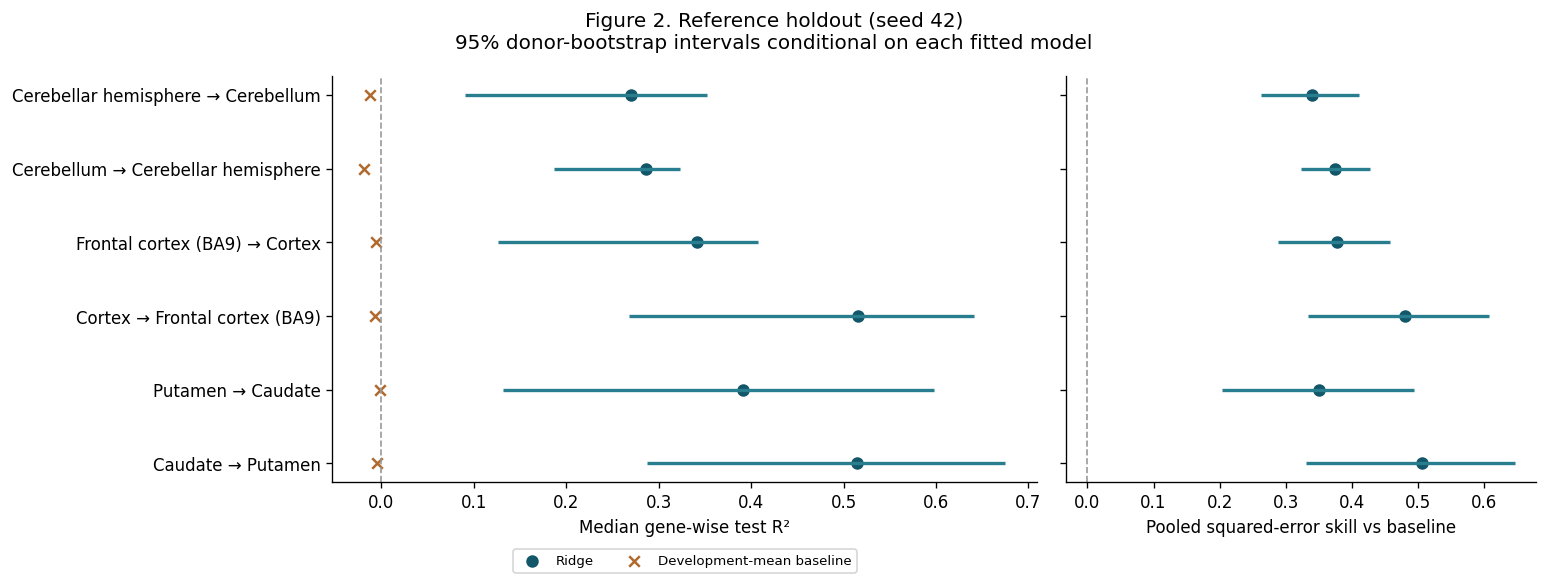

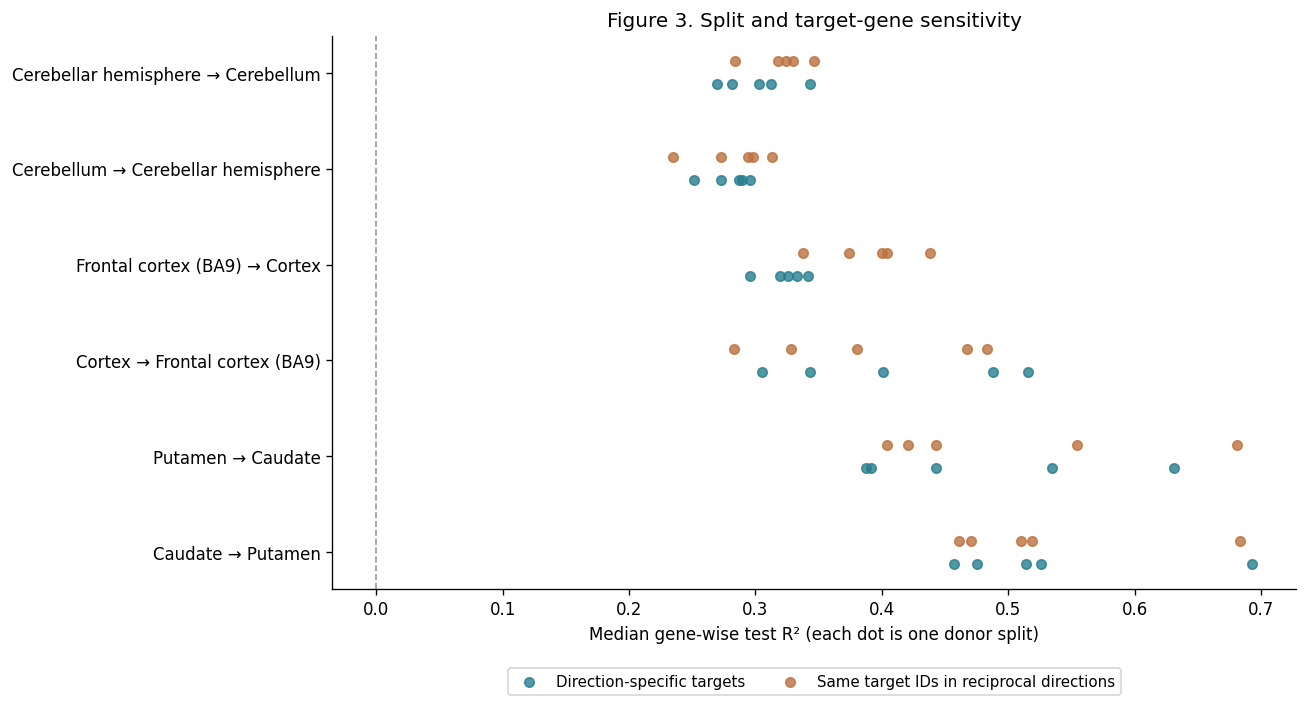

Compact report ready: 4.8 MB. Use its final figures and Methods. The full archive contains the same fitted models and numeric results.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# Compact report export and final figure layout. No model is refitted here.
r=primary.reset_index(drop=True); yy=np.arange(len(r))
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True,gridspec_kw={'width_ratios':[1.5,1]})
axes[0].hlines(yy,r.r2_ci_low,r.r2_ci_high,color='#287d8e',lw=2)
axes[0].scatter(r.median_gene_r2,yy,color='#125669',s=42,label='Ridge')
axes[0].scatter(r.baseline_median_gene_r2,yy,marker='x',color='#b06a2e',s=40,label='Development-mean baseline')
axes[0].set_yticks(yy,[direction(a,b) for a,b in zip(r.source,r.target)])
axes[0].set_xlabel('Median gene-wise test R²')
axes[0].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.15),ncol=2)
axes[1].hlines(yy,r.skill_ci_low,r.skill_ci_high,color='#287d8e',lw=2)
axes[1].scatter(r.skill,yy,color='#125669',s=42)
axes[1].set_xlabel('Pooled squared-error skill vs baseline')
for ax in axes: ax.axvline(0,color='#999999',ls='--',lw=1)
fig.suptitle('Figure 2. Reference holdout (seed 42)\n95% donor-bootstrap intervals conditional on each fitted model',fontsize=12)
fig.tight_layout(); save_figure(fig,'figure_2_primary_prediction')
fig,ax=plt.subplots(figsize=(11,6))
for i,(a,b) in enumerate(PAIRS):
    for mode,offset,color in [('primary',-.12,'#287d8e'),('common_targets',.12,'#bb713e')]:
        vals=results.loc[(results.source==a)&(results.target==b)&(results.analysis==mode),'median_gene_r2'].to_numpy()
        ax.scatter(vals,np.full(len(vals),i+offset),color=color,s=32,alpha=.8,label={'primary':'Direction-specific targets','common_targets':'Same target IDs in reciprocal directions'}[mode] if i==0 else None)
ax.set_yticks(range(len(PAIRS)),[direction(a,b) for a,b in PAIRS]); ax.axvline(0,color='#999999',ls='--',lw=1)
ax.set(xlabel='Median gene-wise test R² (each dot is one donor split)',title='Figure 3. Split and target-gene sensitivity')
ax.legend(fontsize=9,loc='upper center',bbox_to_anchor=(.5,-.13),ncol=2)
fig.tight_layout(); save_figure(fig,'figure_3_sensitivity')
review_note='\n\nPilot-cohort context: these are internal evaluations in the same GTEx cohort used for pilot work. Seed 42 is reused as a reference, not an independent external validation. Five holdouts overlap. Penalties were selected within the stated finite grid; a boundary optimum does not establish a global optimum.\n'
for name in ['Arai_Methods.md','Team_Handoff.md']:
    path=OUT/'documents'/name
    text=path.read_text(encoding='utf-8')
    if 'Pilot-cohort context:' not in text: path.write_text(text+review_note,encoding='utf-8')
compact_path=BASE/'GTEx_Arai_Report.zip'
with zipfile.ZipFile(compact_path,'w',zipfile.ZIP_DEFLATED) as archive:
    for path in OUT.rglob('*'):
        if path.is_file() and path.relative_to(OUT).parts[0] not in ('models','predictions'):
            archive.write(path,path.relative_to(OUT))
print(f'Compact report ready: {compact_path.stat().st_size / 1e6:.1f} MB. Use its final figures and Methods. The full archive contains the same fitted models and numeric results.')
from google.colab import files
files.download(str(compact_path))
